<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_085_loss_functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 85/365 — Loss Functions: MSE vs Cross-Entropy

## Interview question
**Why do we usually use MSE for regression and Cross-Entropy for classification?**

Yesterday we learned that the output activation depends on the task.

Today we add the other half of training:

**Loss Function**

A loss function measures:

> How wrong is the model's prediction?

Training changes weights and biases to reduce this loss.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Mean Squared Error — MSE

For regression:

`MSE = mean((y - ŷ)²)`

Example:

Actual value = `500`

Prediction = `470`

Error = `30`

Squared error = `900`


In [2]:
y_true=np.array([500,700,900])
y_pred=np.array([470,760,880])

mse=np.mean((y_true-y_pred)**2)

print("MSE =",mse)


MSE = 1633.3333333333333


### Why square the error?

Squaring:

- makes positive and negative errors contribute positively
- penalizes larger errors more strongly
- provides a smooth objective for optimization

But MSE is also sensitive to outliers.


## 2. Binary Cross-Entropy

For binary classification:

`BCE = -[y log(p) + (1-y) log(1-p)]`

where:

- `y` is the true class: 0 or 1
- `p` is the predicted probability of class 1


In [3]:
def binary_cross_entropy(y,p):
    eps=1e-12
    p=np.clip(p,eps,1-eps)
    return -(y*np.log(p)+(1-y)*np.log(1-p))

for p in [0.9,0.6,0.1]:
    print(
        f"True y=1, predicted p={p}:",
        round(binary_cross_entropy(1,p),3)
    )


True y=1, predicted p=0.9: 0.105
True y=1, predicted p=0.6: 0.511
True y=1, predicted p=0.1: 2.303


## 3. Confidence matters

For `y = 1`:

### Prediction = 0.9

`-log(0.9) ≈ 0.105`

Confident and correct → small loss.

### Prediction = 0.6

`-log(0.6) ≈ 0.511`

Correct direction, lower confidence → larger loss.

### Prediction = 0.1

`-log(0.1) ≈ 2.303`

Confidently wrong → very large loss.

Cross-entropy strongly punishes confident wrong predictions.


## 4. Compare MSE and Cross-Entropy

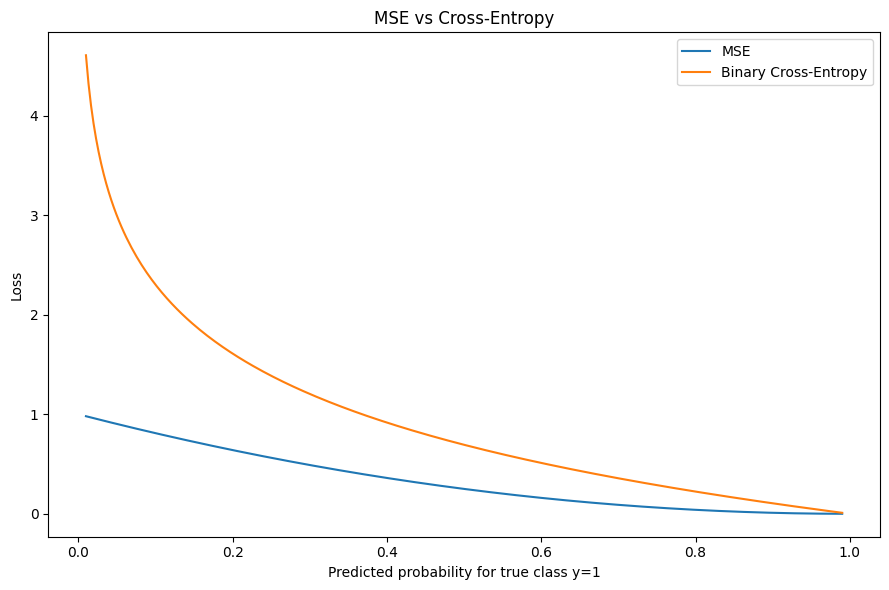

In [4]:
p=np.linspace(0.01,0.99,300)

mse_loss=(1-p)**2
bce_loss=-np.log(p)

plt.figure(figsize=(9,6))
plt.plot(p,mse_loss,label="MSE")
plt.plot(p,bce_loss,label="Binary Cross-Entropy")
plt.xlabel("Predicted probability for true class y=1")
plt.ylabel("Loss")
plt.title("MSE vs Cross-Entropy")
plt.legend()
plt.tight_layout()
plt.show()


## 5. Can MSE be used for classification?

Technically yes, but it is usually not preferred.

With Sigmoid + MSE, gradients can become especially weak when predictions are confidently wrong.

Cross-entropy is naturally aligned with probabilistic classification and usually gives a stronger optimization signal.

Common pairing:

`Sigmoid + Binary Cross-Entropy`


## 6. Multiclass Cross-Entropy

Suppose the true class is `Dog`.

Model output:

- Cat = 0.05
- Dog = 0.90
- Horse = 0.05

Loss:

`-log(0.90) ≈ 0.105`

If Dog received only `0.05` probability:

`-log(0.05) ≈ 2.996`


In [5]:
for p_true in [0.90,0.05]:
    print(
        f"Probability assigned to true class = {p_true}:",
        round(-np.log(p_true),3)
    )


Probability assigned to true class = 0.9: 0.105
Probability assigned to true class = 0.05: 2.996


## 7. Softmax + Cross-Entropy

For mutually exclusive multiclass classification:

`logits → Softmax → probabilities → Cross-Entropy`

In practice, deep-learning libraries often combine Softmax/log operations internally for numerical stability.

Important implementation detail:

- PyTorch `CrossEntropyLoss` expects raw logits.
- TensorFlow losses can use `from_logits=True`.

Do not manually apply Softmax first when the chosen loss already expects logits.


## 8. Loss vs Metric

### Loss

Used by the optimizer during training.

Examples:

- MSE
- Cross-Entropy

### Metric

Used to evaluate the model in a human-friendly way.

Examples:

- Accuracy
- Precision
- Recall
- F1
- MAE

A classifier may optimize cross-entropy while reporting F1.


## 9. Pairing guide

| Task | Output | Typical Loss |
|---|---|---|
| Regression | Numeric value | MSE / MAE |
| Binary Classification | Sigmoid | Binary Cross-Entropy |
| Multiclass Classification | Softmax / logits | Cross-Entropy |
| Multilabel Classification | Independent Sigmoids | Binary Cross-Entropy per label |


## Enterprise intuition

### Regression
Predict demand, cost, duration, or transaction value.

### Binary Classification
Predict fraud vs genuine, churn vs stay, approve vs reject.

### Multiclass Classification
Predict ticket category, document type, or product class.

The loss must match the prediction task and output representation.


## Interview-ready answer

**Why is Cross-Entropy preferred over MSE for classification?**

Cross-entropy is designed for probabilistic classification.

It strongly penalizes confident wrong predictions and, when paired with Sigmoid or Softmax-style outputs, provides a useful gradient signal.

MSE is naturally suited to continuous regression errors and can lead to weaker training behavior for classification.


## What does this teach?

- A loss function measures prediction error.
- MSE is common for regression.
- Cross-entropy is common for classification.
- Cross-entropy strongly penalizes confident wrong predictions.
- Binary classification commonly uses Sigmoid + BCE.
- Multiclass classification commonly uses logits/Softmax + Cross-Entropy.
- Loss and metric are not necessarily the same.

> **Forward propagation tells us what the model predicted. The loss function tells us how wrong that prediction was.**


## References

- https://www.deeplearningbook.org/
- https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
- https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html
- https://www.tensorflow.org/api_docs/python/tf/keras/losses
